29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
FASHION-MNIST DATASET
Training Images: 60000
Testing Images: 10000

TRAINING ORIGINAL CNN MODEL
Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.7999 - loss: 0.5602 - val_accuracy: 0.8542 - val_loss: 0.3964
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8700 - loss: 0.3607 - val_accuracy: 0.8690 - val_loss: 0.3557
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8858 - loss: 0.3157 - val_accuracy: 0.8802 - val_loss: 0.3251

Original CNN Accuracy: 87.68 %
Saved artifact at '/tmp/tmpjam0x3n2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  135704677821968:

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(



MODEL COMPRESSION RESULTS
FP32 Model Size: 0.863 MB
INT8 Model Size: 0.226 MB
Size Reduction: 73.84 %
Compression Ratio: 3.82 :1

EVALUATING BOTH MODELS


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



ACCURACY COMPARISON
FP32 Model Accuracy: 88.3 %
INT8 Model Accuracy: 88.2 %

INFERENCE PERFORMANCE
FP32 Inference Time: 0.108 ms
INT8 Inference Time: 0.131 ms

QUANTIZATION VERIFICATION
FP32 Input Type: <class 'numpy.float32'>
INT8 Input Type: <class 'numpy.uint8'>
INT8 Output Type: <class 'numpy.uint8'>


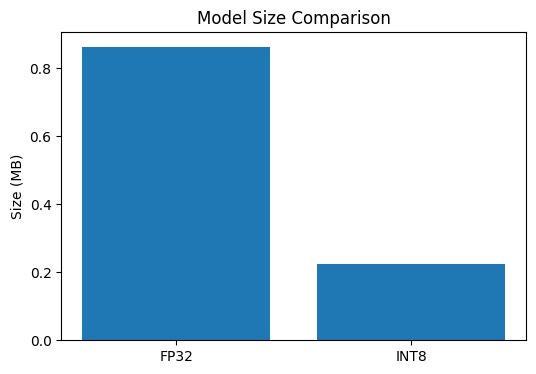

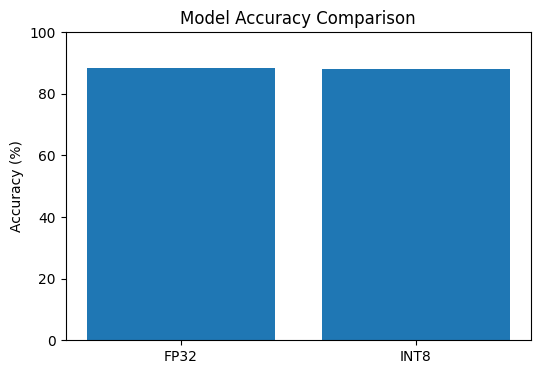

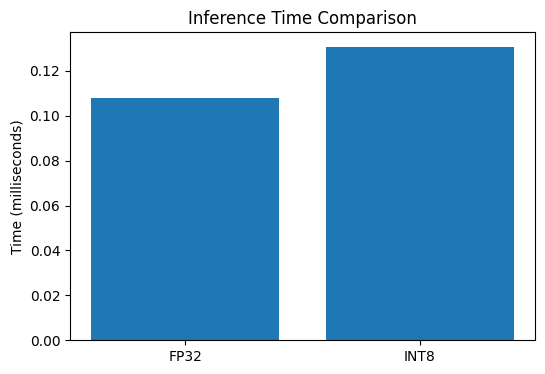

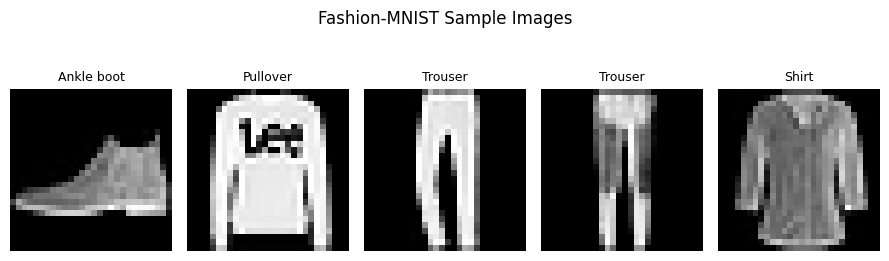


DEPLOYMENT DEMONSTRATION
Compressed Model: model_int8.tflite
Format: TensorFlow Lite
Quantization: INT8
Runtime: LiteRT
Deployment Target: Resource-Constrained Devices
Model compression completed successfully.


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

tf.get_logger().setLevel("ERROR")

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("FASHION-MNIST DATASET")
print("Training Images:", len(x_train))
print("Testing Images:", len(x_test))

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

print("\nTRAINING ORIGINAL CNN MODEL")

model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1)

original_loss, original_accuracy = model.evaluate(
    x_test, y_test, verbose=0)

print("\nOriginal CNN Accuracy:", round(original_accuracy * 100, 2), "%")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
fp32_model = converter.convert()
with open("model_fp32.tflite", "wb") as f:
    f.write(fp32_model)

def representative_dataset():
    for image in x_train[:300]:
        yield [image[np.newaxis, ...].astype(np.float32)]
print("\nAPPLYING INT8 QUANTIZATION")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

int8_model = converter.convert()

with open("model_int8.tflite", "wb") as f:
    f.write(int8_model)

fp32_size = os.path.getsize("model_fp32.tflite") / (1024 * 1024)
int8_size = os.path.getsize("model_int8.tflite") / (1024 * 1024)

reduction = ((fp32_size - int8_size) / fp32_size) * 100
compression_ratio = fp32_size / int8_size

print("\nMODEL COMPRESSION RESULTS")
print("FP32 Model Size:", round(fp32_size, 3), "MB")
print("INT8 Model Size:", round(int8_size, 3), "MB")
print("Size Reduction:", round(reduction, 2), "%")
print("Compression Ratio:", round(compression_ratio, 2), ":1")

fp32_interpreter = tf.lite.Interpreter(model_path="model_fp32.tflite")
int8_interpreter = tf.lite.Interpreter(model_path="model_int8.tflite")

fp32_interpreter.allocate_tensors()
int8_interpreter.allocate_tensors()

def evaluate_tflite(interpreter, images, labels):
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    correct = 0

    for image, label in zip(images, labels):
        image = image[np.newaxis, ...]

        if input_details["dtype"] == np.uint8:
            scale, zero_point = input_details["quantization"]
            image = np.round(image / scale + zero_point)
            image = np.clip(image, 0, 255).astype(np.uint8)
        else:
            image = image.astype(np.float32)

        interpreter.set_tensor(input_details["index"], image)
        interpreter.invoke()

        output = interpreter.get_tensor(output_details["index"])
        prediction = np.argmax(output)

        if prediction == label:
            correct += 1

    return correct / len(labels)

print("\nEVALUATING BOTH MODELS")

total = 2000

fp32_accuracy = evaluate_tflite(
    fp32_interpreter, x_test[:total], y_test[:total])

int8_accuracy = evaluate_tflite(
    int8_interpreter, x_test[:total], y_test[:total])

print("\nACCURACY COMPARISON")
print("FP32 Model Accuracy:", round(fp32_accuracy * 100, 2), "%")
print("INT8 Model Accuracy:", round(int8_accuracy * 100, 2), "%")

def benchmark(interpreter, image):
    input_details = interpreter.get_input_details()[0]
    image = image[np.newaxis, ...]
    if input_details["dtype"] == np.uint8:
        scale, zero_point = input_details["quantization"]
        image = np.round(image / scale + zero_point)
        image = np.clip(image, 0, 255).astype(np.uint8)
    else:
        image = image.astype(np.float32)
    def inference():
        interpreter.set_tensor(input_details["index"], image)
        interpreter.invoke()
    for _ in range(10):
        inference()
    start = time.perf_counter()
    for _ in range(100):
        inference()
    return (time.perf_counter() - start) / 100 * 1000

fp32_time = benchmark(fp32_interpreter, x_test[0])
int8_time = benchmark(int8_interpreter, x_test[0])

print("\nINFERENCE PERFORMANCE")
print("FP32 Inference Time:", round(fp32_time, 3), "ms")
print("INT8 Inference Time:", round(int8_time, 3), "ms")
print("\nQUANTIZATION VERIFICATION")
print("FP32 Input Type:", fp32_interpreter.get_input_details()[0]["dtype"])
print("INT8 Input Type:", int8_interpreter.get_input_details()[0]["dtype"])
print("INT8 Output Type:", int8_interpreter.get_output_details()[0]["dtype"])
plt.figure(figsize=(6, 4))
plt.bar(["FP32", "INT8"], [fp32_size, int8_size])
plt.title("Model Size Comparison")
plt.ylabel("Size (MB)")
plt.show()
plt.figure(figsize=(6, 4))
plt.bar(
    ["FP32", "INT8"],
    [fp32_accuracy * 100, int8_accuracy * 100])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(
    ["FP32", "INT8"],
    [fp32_time, int8_time])
plt.title("Inference Time Comparison")
plt.ylabel("Time (milliseconds)")
plt.show()

plt.figure(figsize=(9, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(class_names[y_test[i]], fontsize=9)
    plt.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()

print("\nDEPLOYMENT DEMONSTRATION")
print("Compressed Model: model_int8.tflite")
print("Format: TensorFlow Lite")
print("Quantization: INT8")
print("Runtime: LiteRT")
print("Deployment Target: Resource-Constrained Devices")
print("Model compression completed successfully.")